```
Домашнее задание 1
Курс: "Основы глубинного обучения"
Выполнила: Максименко Полина
```

# Классификация текстов с помощью RNN (PyTorch)

## Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

## Часть A. Эксперименты с гиперпараметрами

### 1. Окружение

In [1]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [2]:
import re
import random
import time
import copy
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
from IPython.display import display

In [3]:
# устанавливаем random seed для numpy и torch
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

# проверяем доступность GPU
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cuda


### 2. Загрузка данных

*Русский датасет эмоций (E-Kulture)* `Kostya165/ru_emotion_dvach` содержит более 60 тыс. сообщений с форума 2ch, размеченные по 5 эмоциональным/тональным категориям: агрессия, тревожность, сарказм, положительное, нейтральное.

Исходные данные были взяты из публичного датасета `marriamaslova/toxic_dvach` и дополнительно обработаны с использованием модели YandexGPT-5-Lite-8B для генерации различных эмоциональных версий текстов.

Датасет сбалансирован по классам.

In [4]:
dataset = load_dataset("Kostya165/ru_emotion_dvach")

print(dataset)
print("\nПример:", dataset['train'][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 59061
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2507
    })
})

Пример: {'text': 'Я боюсь, что из-за контроля сварных соединений я могу пропустить что-то важное, и тогда будут большие проблемы.', 'label': 'anxiety'}


In [5]:
# пакуем данные в кортежи метка + текст
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['validation']['label'],
    dataset['validation']['text']
))

# проверяем на None
train_data = [
    (label, text)
    for label, text in train_data
    if isinstance(text, str) and text.strip()
]

test_data = [
    (label, text)
    for label, text in test_data
    if isinstance(text, str) and text.strip()
]

# выделяем валидационную выборку
train_data, val_data = train_test_split(
    train_data,
    test_size=0.1,
    random_state=SEED,
    stratify=[label for label, _ in train_data]
)

print(f"Обучающих примеров: {len(train_data)}")
print(f"Валидационных примеров: {len(val_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 53148
Валидационных примеров: 5906
Тестовых примеров: 2507

Распределение меток: Counter({'anxiety': 10682, 'positive': 10670, 'aggression': 10638, 'neutral': 10634, 'sarcasm': 10524})


### 3. Визуализация данных

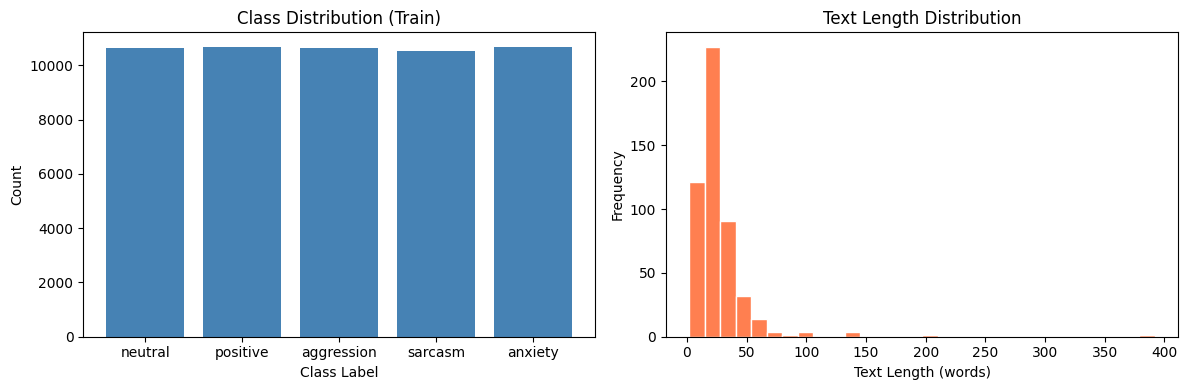

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# создаем частотный словарь по классам
labels = [label for label, _ in train_data]
label_counts = Counter(labels)

# выводим распределение классов
axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3, 4])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

# выводим распределение длины текстов
axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

Классы разделены ровно, т.к. были искусственно сбалансированы. Преобладают короткие тексты до 50 слов, но изредка встречаются и подлиннее.

In [7]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label '{label}'] {text[:150]}...")


=== Примеры ===
[Label 'neutral'] Домофо н (под этим чаще всего подразумевается Домофонная система) электронная система, состоящая из устройств, передающих сигнал от вызывного блока к ...
[Label 'positive'] Надеюсь, люди поймут, что Знамя Победы и власовский флаг — это символы с разным значением, и не будут ставить их рядом....
[Label 'aggression'] дебил-куколд Значение знаешь?...


### 4. Токенизация и словарь

In [8]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [9]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [10]:
# специальные токены
PAD_IDX = 0
UNK_IDX = 1

# преобразование меток классов
label2id = {
    'aggression': 0,
    'anxiety': 1,
    'sarcasm': 2,
    'positive': 3,
    'neutral': 4,
}
id2label = {value: key for key, value in label2id.items()}
class_names = [id2label[i] for i in range(len(label2id))]
NUM_CLASSES = len(class_names)

def label_pipeline(label):
    if isinstance(label, str):
        return label2id[label]
    return int(label)

def make_text_pipeline(vocab, max_len):
    def text_pipeline(text):
        tokens = tokenizer(text)
        ids = [vocab.get(token, UNK_IDX) for token in tokens]
        ids = ids[:max_len]
        if len(ids) == 0:
            ids = [UNK_IDX]
        return ids
    return text_pipeline

vocab_cache = {}

def get_vocab(min_freq):
    if min_freq not in vocab_cache:
        vocab_cache[min_freq] = build_vocab_from_iterator(
            yield_tokens(train_data), min_freq=min_freq
        )
    return vocab_cache[min_freq]

### 5. Dataset и DataLoader

In [11]:
class RuEmotionDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [12]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [13]:
# создаем DataLoader для обучающей, валидационной и тестовой выборок
def make_loaders(vocab, max_len, batch_size):
    text_pipeline = make_text_pipeline(vocab, max_len)
    train_dataset = RuEmotionDataset(train_data, text_pipeline, label_pipeline)
    val_dataset = RuEmotionDataset(val_data, text_pipeline, label_pipeline)
    test_dataset = RuEmotionDataset(test_data, text_pipeline, label_pipeline)

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        collate_fn=collate_batch, num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        collate_fn=collate_batch, num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False,
        collate_fn=collate_batch, num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    return train_loader, val_loader, test_loader

### 6. RNN-модель

In [14]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False,
        model_type="RNN"
    ):
        super().__init__()

        # преобразуем токены в эмбеддинги
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        # добавляем возможность выбрать LSTM или GRU (для сравнения)
        if model_type == 'RNN':
            recurrent_layer = nn.RNN
        elif model_type == 'LSTM':
            recurrent_layer = nn.LSTM
        elif model_type == 'GRU':
            recurrent_layer = nn.GRU
        else:
            raise ValueError('Неизвестный тип модели: ' + model_type)

        self.model_type = model_type
        self.rnn = recurrent_layer(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        # исключаем доп. токены из рекуррентной обработки
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        # LSTM возвращает и скрытое состояние, и состояние памяти
        if self.model_type == 'LSTM':
            hidden, cell = hidden

        # объединяем скрытые состояния двух направлений для bidirectional
        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

### 7. Обучение и проверка

In [15]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [16]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

### 8. Функции для экспериментов

In [19]:
def run_experiment(min_freq=2, max_len=64, batch_size=32,
                   embed_dim=64, hidden_dim=64, num_layers=1,
                   bidirectional=False, lr=1e-3, num_epochs=3,
                   dropout=0.2, seed=SEED, model_type='RNN'):
    """Создает и обучает модель с заданными параметрами,
    измеряет время обучения и сохраняет историю метрик"""

    set_seed(seed)
    vocab = get_vocab(min_freq)
    train_loader, val_loader, _ = make_loaders(
        vocab, max_len, batch_size
    )

    model = RNNClassifier(
        vocab_size=len(vocab),
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_classes=NUM_CLASSES,
        num_layers=num_layers,
        dropout=dropout,
        bidirectional=bidirectional,
        model_type=model_type
    ).to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    epoch_times = []

    for epoch in range(num_epochs):
        if device.type == 'cuda':
            torch.cuda.synchronize()

        start = time.perf_counter()
        train_loss, train_acc = train_epoch(
            model, train_loader, optimizer, criterion
        )

        if device.type == 'cuda':
            torch.cuda.synchronize()

        epoch_times.append(time.perf_counter() - start)

        val_loss, val_acc, _, _ = evaluate(
            model, val_loader, criterion
        )

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Epoch {epoch + 1}/{num_epochs} | '
              f'Train Loss: {train_loss:.4f} | '
              f'Train Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f} | '
              f'Val Acc: {val_acc:.4f}')

    result = {
        'vocab_size': len(vocab),
        'params': sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        ),
        'epoch_time': np.mean(epoch_times),
        'epochs': num_epochs,
        'val_loss': history['val_loss'][-1],
        'val_acc': history['val_acc'][-1],
    }

    return result, model, history


def run_config(title, configs, base_result, **base):
    """Запускает группу вариантов одного параметра
    и переиспользует уже рассчитанную базовую конфигурацию"""
    rows = []
    for value, changes in configs:
        config = base.copy()
        config.update(changes)

        # версию с базовым набором параметров копируем для всех групп
        if config == base:
            result = base_result.copy()
        else:
            print(f'\n{title} = {value}')
            result, experiment_model, experiment_history = run_experiment(**config)
            del experiment_model

        row = config.copy()
        row.update(result)
        row['parameter'] = title
        row['value'] = str(value)
        rows.append(row)

    return pd.DataFrame(rows)

### 9. Проведение экспериментов

In [22]:
BASE = dict(
    min_freq=2, max_len=32, batch_size=32,
    embed_dim=64, hidden_dim=64, num_layers=1,
    bidirectional=False, lr=1e-3, num_epochs=3,
    dropout=0.2, seed=SEED, model_type='RNN'
)

base_result, base_model, base_history = run_experiment(**BASE)
del base_model # удаляем модель, храним только результаты

Evaluating: 100%|██████████| 185/185 [00:00<00:00, 290.32it/s]


Epoch 1/3 | Train Loss: 1.2160 | Train Acc: 0.5097 | Val Loss: 0.8928 | Val Acc: 0.6746


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 324.71it/s]


Epoch 2/3 | Train Loss: 0.8843 | Train Acc: 0.6876 | Val Loss: 0.7360 | Val Acc: 0.7482


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 322.42it/s]

Epoch 3/3 | Train Loss: 0.7448 | Train Acc: 0.7490 | Val Loss: 0.6810 | Val Acc: 0.7726


In [23]:
# запускаем все эксперименты, меняя по одному значению одного параметра за раз
exp_results = [
    run_config('MIN_FREQ', [('2', {'min_freq': 2}),
                           ('5', {'min_freq': 5}),
                           ('10', {'min_freq': 10})], base_result, **BASE),

    # max_len берем на порядок короче, т.к. тексты в датасете в основном короткие
    run_config('MAX_LEN', [('32', {'max_len': 32}),
                          ('64', {'max_len': 64}),
                          ('128', {'max_len': 128})], base_result, **BASE),

    run_config('BATCH_SIZE', [('32', {'batch_size': 32}),
                             ('64', {'batch_size': 64}),
                             ('128', {'batch_size': 128})], base_result, **BASE),

    run_config('EMBED/HIDDEN', [('64', {'embed_dim': 64}),
                            ('128', {'embed_dim': 128}),
                            ('256', {'embed_dim': 256})], base_result, **BASE),

    run_config('NUM_LAYERS', [('1', {'num_layers': 1}),
                             ('2', {'num_layers': 2})], base_result, **BASE),

    run_config('BIDIRECTIONAL', [('False', {'bidirectional': False}),
                                ('True', {'bidirectional': True})], base_result, **BASE),

    run_config('LR', [('1e-3', {'lr': 1e-3}),
                     ('5e-4', {'lr': 5e-4}),
                     ('1e-4', {'lr': 1e-4})], base_result, **BASE),
]


MIN_FREQ = 5


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 298.08it/s]


Epoch 1/3 | Train Loss: 1.2265 | Train Acc: 0.4992 | Val Loss: 0.9418 | Val Acc: 0.6448


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 312.30it/s]


Epoch 2/3 | Train Loss: 0.8875 | Train Acc: 0.6840 | Val Loss: 0.8137 | Val Acc: 0.7147


...

Epoch 1/3 | Train Loss: 1.5247 | Train Acc: 0.3013 | Val Loss: 1.4676 | Val Acc: 0.3439


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 301.76it/s]


Epoch 2/3 | Train Loss: 1.4137 | Train Acc: 0.3876 | Val Loss: 1.2743 | Val Acc: 0.4710


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 307.85it/s]

Epoch 3/3 | Train Loss: 1.2710 | Train Acc: 0.4719 | Val Loss: 1.1772 | Val Acc: 0.5251


#### Результаты

In [26]:
# табличка с результатами по всем экспериментам
final = pd.concat(exp_results, ignore_index=True)
display(final[['parameter', 'value', 'vocab_size', 'params', 'epoch_time',
               'val_loss', 'val_acc']].round(4))

,parameter,value,vocab_size,params,epoch_time,val_loss,val_acc
0,MIN_FREQ,2,49186,3156549,14.1159,0.6810,0.7726
1,MIN_FREQ,5,25001,1608709,11.3944,0.7016,0.7714
2,MIN_FREQ,10,12006,777029,10.8290,0.6679,0.7794
3,MAX_LEN,32,49186,3156549,14.1159,0.6810,0.7726
4,MAX_LEN,64,49186,3156549,14.3924,0.6491,0.7933
5,MAX_LEN,128,49186,3156549,16.9961,0.6310,0.8005
6,BATCH_SIZE,32,49186,3156549,14.1159,0.6810,0.7726
7,BATCH_SIZE,64,49186,3156549,7.4617,0.7167,0.7609
8,BATCH_SIZE,128,49186,3156549,5.0938,0.7875,0.7330
9,EMBED/HIDDEN,64,49186,3156549,14.1159,0.6810,0.7726


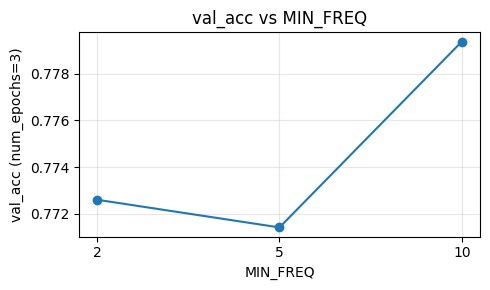

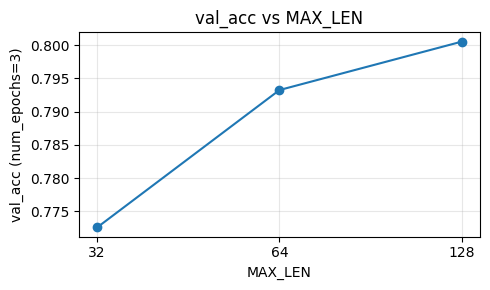

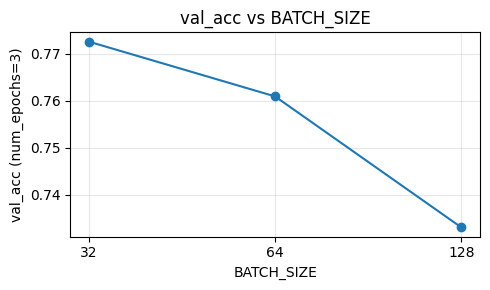

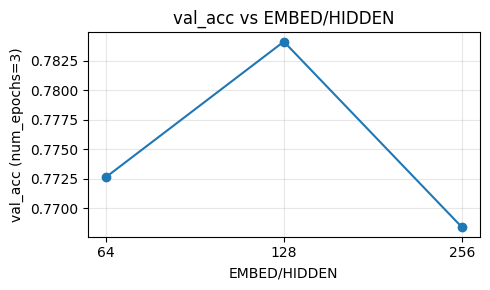

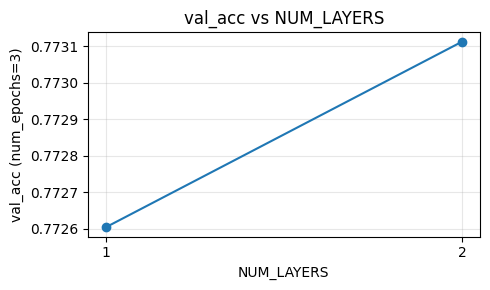

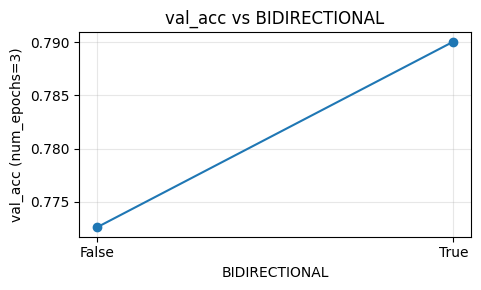

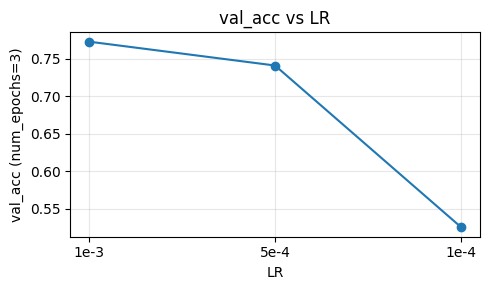

In [27]:
# строим графики зависимости val_acc от значений параметров
for title in final['parameter'].unique():
    group = final[final['parameter'] == title]
    plt.figure(figsize=(5, 3))
    plt.plot(group['value'], group['val_acc'], marker='o')
    plt.xlabel(title)
    plt.ylabel('val_acc (num_epochs=3)')
    plt.title(f'val_acc vs {title}')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### 10. Обучение "лучшей" модели

Обучаем модель с комбинацией параметров, где у каждого было наибольшее значение val_acc в группе. !NB Модель может не быть лучшей из всех возможных вариантов, но интересно, какое будет качество в такой конфигурации. Для поиска самого эффективного варианта нужно перебирать значения гиперпараметров совместно в разных комбинациях, например, с помощью GridSearch.

In [28]:
group_parameters = {
    'MIN_FREQ': ['min_freq'],
    'MAX_LEN': ['max_len'],
    'BATCH_SIZE': ['batch_size'],
    'EMBED/HIDDEN': ['embed_dim', 'hidden_dim'],
    'NUM_LAYERS': ['num_layers'],
    'BIDIRECTIONAL': ['bidirectional'],
    'LR': ['lr'],
}

best_config = BASE.copy()

for group_name, parameters in group_parameters.items():
    group = final[final['parameter'] == group_name]

    best_row = group.sort_values(
        ['val_acc', 'val_loss'],
        ascending=[False, True]
    ).iloc[0]

    for parameter in parameters:
        best_config[parameter] = best_row[parameter]

for parameter in ['min_freq', 'max_len', 'batch_size',
                  'embed_dim', 'hidden_dim', 'num_layers', 'seed']:
    best_config[parameter] = int(best_config[parameter])

best_config['bidirectional'] = bool(best_config['bidirectional'])
best_config['lr'] = float(best_config['lr'])
best_config['dropout'] = float(best_config['dropout'])
best_config['num_epochs'] = 3

print('Комбинация лучших значений по группам:')
for parameter, value in best_config.items():
    print(f'{parameter}: {value}')

MIN_FREQ = best_config['min_freq']
MAX_LEN = best_config['max_len']
BATCH_SIZE = best_config['batch_size']
EMBED_DIM = best_config['embed_dim']
HIDDEN_DIM = best_config['hidden_dim']
NUM_LAYERS = best_config['num_layers']
BIDIRECTIONAL = best_config['bidirectional']
LEARNING_RATE = best_config['lr']
NUM_EPOCHS = 3
DROPOUT = best_config['dropout']

set_seed()
vocab = get_vocab(MIN_FREQ)
text_pipeline = make_text_pipeline(vocab, MAX_LEN)
train_loader, val_loader, test_loader = make_loaders(
    vocab, MAX_LEN, BATCH_SIZE
)

model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)
print('Размер словаря:', len(vocab))
print('Количество параметров:', sum(p.numel() for p in model.parameters()))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}
epoch_times = []

for epoch in range(NUM_EPOCHS):
    if device.type == 'cuda':
        torch.cuda.synchronize()

    start = time.perf_counter()
    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, criterion
    )

    if device.type == 'cuda':
        torch.cuda.synchronize()

    epoch_times.append(time.perf_counter() - start)

    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch + 1}/{NUM_EPOCHS} | '
          f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | '
          f'Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}')

Комбинация лучших значений по группам:
min_freq: 10
max_len: 128
batch_size: 32
embed_dim: 128
hidden_dim: 64
num_layers: 2
bidirectional: True
lr: 0.001
num_epochs: 3
dropout: 0.2
seed: 42
model_type: RNN
RNNClassifier(
  (embedding): Embedding(12006, 128, padding_idx=0)
  (rnn): RNN(128, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (fc): Linear(in_features=128, out_features=5, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Размер словаря: 12006
Количество параметров: 1587077


Evaluating: 100%|██████████| 185/185 [00:01<00:00, 124.45it/s]


Epoch 1/3 | Train Loss: 0.8884 | Train Acc: 0.6675 | Val Loss: 0.6769 | Val Acc: 0.7577


Evaluating: 100%|██████████| 185/185 [00:01<00:00, 126.24it/s]


Epoch 2/3 | Train Loss: 0.6365 | Train Acc: 0.7776 | Val Loss: 0.5472 | Val Acc: 0.8156


Evaluating: 100%|██████████| 185/185 [00:01<00:00, 119.65it/s]

Epoch 3/3 | Train Loss: 0.5346 | Train Acc: 0.8187 | Val Loss: 0.5037 | Val Acc: 0.8244


#### Кривые обучения

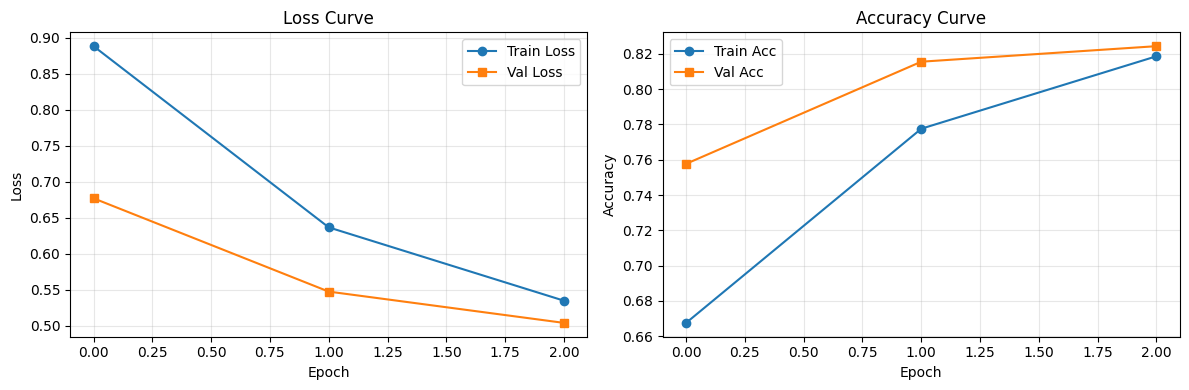

In [29]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

По кривым обучения все хорошо, недо- или переобучения нет.

#### Оценка на тесте

Evaluating: 100%|██████████| 79/79 [00:00<00:00, 124.78it/s]


Test loss: 0.5054
Test accuracy: 0.8221
Test macro-F1: 0.8212
              precision    recall  f1-score   support

  aggression       0.78      0.83      0.81       500
     anxiety       0.87      0.91      0.89       502
     sarcasm       0.86      0.75      0.80       502
    positive       0.80      0.87      0.84       502
     neutral       0.80      0.74      0.77       501

    accuracy                           0.82      2507
   macro avg       0.82      0.82      0.82      2507
weighted avg       0.82      0.82      0.82      2507



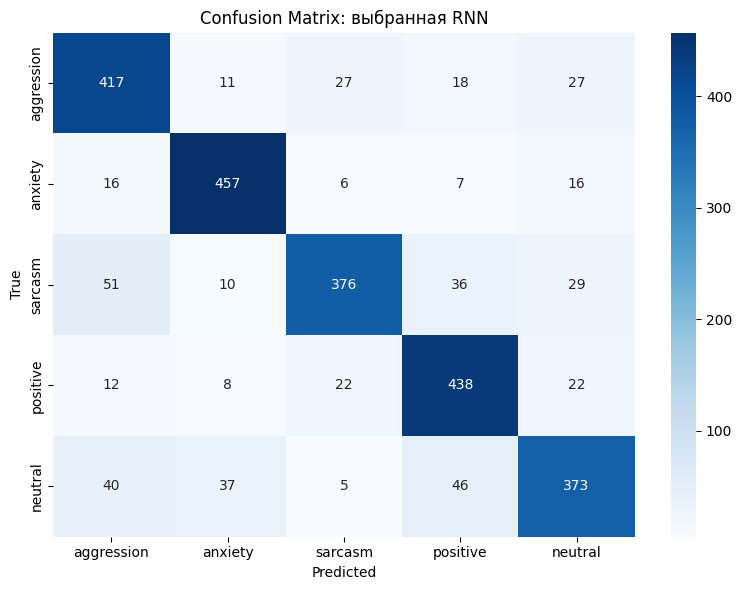

In [30]:
test_loss, test_acc, all_preds, all_labels = evaluate(model, test_loader, criterion)
test_f1 = f1_score(all_labels, all_preds, labels=range(NUM_CLASSES),
                   average='macro', zero_division=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test macro-F1: {test_f1:.4f}')
print(classification_report(
    all_labels, all_preds, labels=range(NUM_CLASSES),
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(all_labels, all_preds, labels=range(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix: выбранная RNN')
plt.tight_layout()
plt.show()

В целом, неплохой уровень качества - macro F1 = 0.82. Ожидаемо, хуже всего распознается класс neutral. С распознаванием сарказма тоже есть проблемы.

## Часть B. Анализ ошибок

In [31]:
# выведем 10 примеров ошибок с текстами, количеством слов и unk
preds_all = np.array(all_preds)
labels_all = np.array(all_labels)
texts_all = [text for _, text in test_data]
wrong = np.where(preds_all != labels_all)[0]
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(wrong, size=min(10, len(wrong)), replace=False)

def unk_ratio(text):
    tokens = tokenizer(text)[:MAX_LEN]
    if len(tokens) == 0:
        return 0.0
    return sum(token not in vocab for token in tokens) / len(tokens)

rows = []
for i in sample_idx:
    tokens = tokenizer(texts_all[i])
    unknown = [token for token in tokens[:MAX_LEN] if token not in vocab]

    rows.append({
        'index': int(i),
        'true': id2label[labels_all[i]],
        'pred': id2label[preds_all[i]],
        'text': texts_all[i][:200],
        'words': len(texts_all[i].split()),
        'unk_ratio': unk_ratio(texts_all[i]),
        'unknown_tokens': ', '.join(unknown[:10]),
    })

errors = pd.DataFrame(rows)
print(f'Всего ошибок: {len(wrong)} из {len(test_data)}')
with pd.option_context('display.max_colwidth', None):
    display(errors)

Всего ошибок: 446 из 2507


,index,true,pred,text,words,unk_ratio,unknown_tokens
0,208,anxiety,positive,"Мы все умрем, жидорептилойды с планеты нибиру скоро захватят нашу планету и устроят казнь всех гоев.",16,0.277778,"жидорептилойды, нибиру, устроят, казнь, гоев"
1,1869,aggression,positive,"Он их скрыл когда-то, но в прошлом году вновь открыл некоторые, чтобы издеваться над старыми друзьями. И новые видосы записывает иногда, чтобы позлорадствовать.",23,0.133333,"скрыл, издеваться, записывает, позлорадствовать"
2,210,neutral,aggression,Мы обсуждаем различные предложения по решению ситуации. Что вы предлагаете?,10,0.000000,
3,1644,aggression,sarcasm,"Снег бывает не так часто за весь год, но каждый раз уборка превращается в ад! У меня двор закрытый, а дорога чистится только тогда, когда мне это удобно. Я снег только сзади в огороде от двери до манг",46,0.094340,"закрытый, чистится, огороде, мангала, вечность"
4,1068,sarcasm,positive,"Дерьмо-мина это баянистая первоапрельская шутка, в которую верят люди, далёкие от армии.",12,0.235294,"мина, баянистая, первоапрельская, далёкие"
5,1053,sarcasm,aggression,"Сидим с другом в летней кафешке, ну прям как короли какие-то. Только вот погода испортится, и будем мы сидеть, как два воробья на ветке.",24,0.096774,"летней, кафешке, воробья"
6,1742,aggression,sarcasm,"Идём дальше. Изучаем второй названный сайт fsa, . Просматриваем весь сайт, открываем преподаватели и что видим: Это какая-то мошенническая схема, наверняка этот человек — шарлатан! Ответил за направле",64,0.160494,"идём, изучаем, названный, fsa, просматриваем, открываем, мошенническая, шарлатан, диетологии, нутрициологии"
7,218,aggression,neutral,"Оружия современного было у них мало, а человеческого мяса много, вот и решили компенсировать",14,0.062500,человеческого
8,513,sarcasm,positive,"Видал новость как в сша в каком то магазе, выкладывали продукты с почти истекшим сроком годности на отдельную полку с огромной скидкой. В итоге и нищуки довольны и за просрочку не ебут. Вот это, я пон",44,0.188679,"магазе, выкладывали, истекшим, годности, отдельную, нищуки, просрочку, ебут, просроченное, скидке"
9,2200,anxiety,aggression,"Бате недавно ставили, многим уже в 40 нужно. А если не повезло с зубами, то и того раньше. Надеюсь, вам не повезло, и ситуация может только ухудшиться",27,0.060606,"бате, ухудшиться"


Заметим, что в датасете встречаются сензитивные тексты с большой долей сленга/слюров. В рассмотренных примерах заметны трудности разграничения сарказма, агрессии и позитивной оценки, особенно когда буквальный смысл отличается от подразумеваемого. В нескольких сообщениях неизвестными оказались важные эмоциональные маркеры, например "издеваться", "позлорадствовать" и "шарлатан", что могло затруднить классификацию. Однако ошибки встречаются и при нулевой доле неизвестных токенов, поэтому недостаточный словарь - не единственное возможное объяснение. Некоторые сообщения допускают несколько интерпретаций из-за малого объема текста и недостаточного контекста.

In [32]:
# самые частые ошибки по классам
err_df = pd.DataFrame({
    'true': [id2label[i] for i in labels_all[wrong]],
    'pred': [id2label[i] for i in preds_all[wrong]],
    'words': [len(texts_all[i].split()) for i in wrong],
})
print('Самые частые ошибки (true → pred):')
display(err_df.groupby(['true', 'pred']).size().sort_values(ascending=False).head(10))

comparison = pd.DataFrame({
    'correct': preds_all == labels_all,
    'words': [len(text.split()) for text in texts_all],
    'unk_ratio': [unk_ratio(text) for text in texts_all],
})
display(comparison.groupby('correct').agg(
    count=('words', 'size'),
    mean_words=('words', 'mean'),
    mean_unk_ratio=('unk_ratio', 'mean')
))

Самые частые ошибки (true → pred):


true        pred      
sarcasm     aggression    51
neutral     positive      46
            aggression    40
            anxiety       37
sarcasm     positive      36
            neutral       29
aggression  sarcasm       27
            neutral       27
positive    sarcasm       22
            neutral       22
dtype: int64

,count,mean_words,mean_unk_ratio
correct,,,
False,446,33.177130,0.147722
True,2061,25.727317,0.105186


Сарказм чаще всего ошибочно распознается как агрессия (51 случай), позитив (36) или нейтральность (29), что может указывать на трудности распознавания иронии. Нейтральные сообщения получают эмоциональные метки positive (46), aggression (40) и anxiety (37), тогда как агрессия смешивается с сарказмом (27) и нейтральностью (27). Позитивные сообщения также ошибочно классифицируются как сарказм или нейтральность — по 22 случая. Ошибочные ответы связаны в среднем с более длинными текстами (33,2 VS 25,7 слов) и большей долей неизвестных токенов (14,8% VS 10,5%), однако эти различия не доказывают причины ошибок.

## Часть C. Улучшение архитектуры

Обучим все варианты архитектуры для сравнения с RNN: GRU и LSTM однонаправленные и двунаправленные.

In [33]:
rnn_name = 'BiRNN' if BIDIRECTIONAL else 'RNN'
models = {rnn_name: model}

architecture_rows = [{
    'architecture': rnn_name,
    'vocab_size': len(vocab),
    'params': sum(p.numel() for p in model.parameters()),
    'epoch_time': np.mean(epoch_times),
    'epochs': NUM_EPOCHS,
    'val_loss': history['val_loss'][-1],
    'val_acc': history['val_acc'][-1],
}]

architectures = [
    ('LSTM', 'LSTM', False),
    ('GRU', 'GRU', False),
    ('BiLSTM', 'LSTM', True),
    ('BiGRU', 'GRU', True),
]

for name, model_type, bidirectional in architectures:
    print('\nАрхитектура:', name)

    config = best_config.copy()
    config['model_type'] = model_type
    config['bidirectional'] = bidirectional
    config['num_epochs'] = 3

    result, architecture_model, architecture_history = run_experiment(**config)
    models[name] = architecture_model

    architecture_rows.append({
        'architecture': name,
        'vocab_size': result['vocab_size'],
        'params': result['params'],
        'epoch_time': result['epoch_time'],
        'epochs': config['num_epochs'],
        'val_loss': architecture_history['val_loss'][-1],
        'val_acc': architecture_history['val_acc'][-1],
    })

architecture_results = pd.DataFrame(architecture_rows)
display(architecture_results.round(4))


Архитектура: LSTM


Evaluating: 100%|██████████| 185/185 [00:01<00:00, 173.95it/s]


Epoch 1/3 | Train Loss: 0.7084 | Train Acc: 0.7491 | Val Loss: 0.4730 | Val Acc: 0.8417


Evaluating: 100%|██████████| 185/185 [00:00<00:00, 188.82it/s]


Epoch 2/3 | Train Loss: 0.4136 | Train Acc: 0.8634 | Val Loss: 0.3799 | Val Acc: 0.8771


...

Evaluating: 100%|██████████| 185/185 [00:01<00:00, 123.59it/s]


Epoch 2/3 | Train Loss: 0.3570 | Train Acc: 0.8775 | Val Loss: 0.3375 | Val Acc: 0.8901


Evaluating: 100%|██████████| 185/185 [00:01<00:00, 133.02it/s]

Epoch 3/3 | Train Loss: 0.2797 | Train Acc: 0.9052 | Val Loss: 0.3215 | Val Acc: 0.8938


,architecture,vocab_size,params,epoch_time,epochs,val_loss,val_acc
0,BiRNN,12006,1587077,32.3917,3,0.5037,0.8244
1,LSTM,12006,1620037,23.2398,3,0.3754,0.8806
2,GRU,12006,1599301,22.7707,3,0.3360,0.8860
3,BiLSTM,12006,1736069,34.6805,3,0.3212,0.8925
4,BiGRU,12006,1686405,34.2522,3,0.3215,0.8938


In [34]:
best_architecture = architecture_results.sort_values(
    ['val_acc', 'val_loss'], ascending=[False, True]
).iloc[0]['architecture']
print('Лучшая модель на валидации:', best_architecture)

architecture_predictions = {}
test_rows = []
for name, architecture_model in models.items():
    loss, acc, preds, labels = evaluate(architecture_model, test_loader, criterion)
    macro_f1 = f1_score(labels, preds, labels=range(NUM_CLASSES),
                        average='macro', zero_division=0)
    architecture_predictions[name] = (preds, labels)
    test_rows.append({'architecture': name, 'test_loss': loss,
                      'test_acc': acc, 'test_macro_f1': macro_f1})

architecture_results = architecture_results.merge(pd.DataFrame(test_rows), on='architecture')
display(architecture_results.round(4))


Лучшая модель на валидации: BiGRU


Evaluating: 100%|██████████| 79/79 [00:00<00:00, 117.84it/s]


,architecture,vocab_size,params,epoch_time,epochs,val_loss,val_acc,test_loss,test_acc,test_macro_f1
0,BiRNN,12006,1587077,32.3917,3,0.5037,0.8244,0.5054,0.8221,0.8212
1,LSTM,12006,1620037,23.2398,3,0.3754,0.8806,0.3621,0.8871,0.8870
2,GRU,12006,1599301,22.7707,3,0.3360,0.8860,0.3405,0.8911,0.8912
3,BiLSTM,12006,1736069,34.6805,3,0.3212,0.8925,0.3159,0.8979,0.8979
4,BiGRU,12006,1686405,34.2522,3,0.3215,0.8938,0.3044,0.9023,0.9022


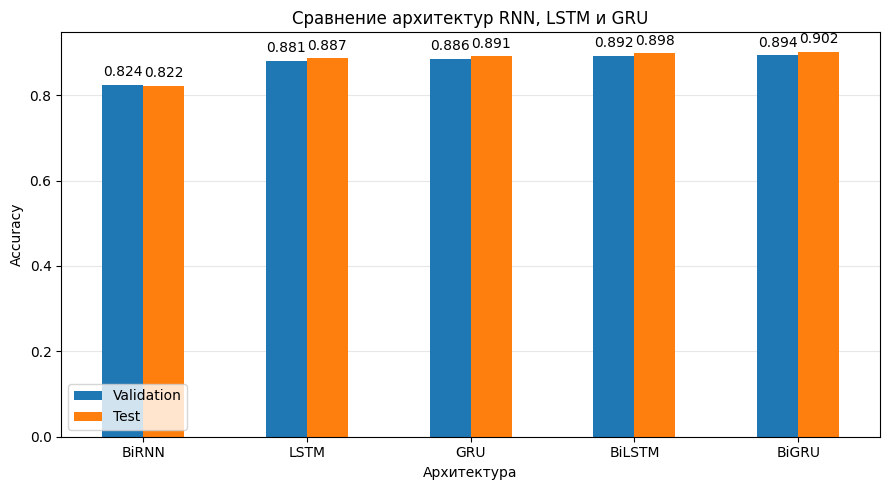

In [35]:
plot_data = architecture_results.set_index('architecture')[['val_acc', 'test_acc']]
ax = plot_data.plot.bar(figsize=(9, 5), rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', padding=4, fontsize=10)

ax.set_ylabel('Accuracy')
ax.set_xlabel('Архитектура')
ax.set_title('Сравнение архитектур RNN, LSTM и GRU')
ax.legend(['Validation', 'Test'])
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

За три эпохи все варианты LSTM и GRU превзошли BiRNN: тестовая accuracy выросла с 82,21% до 88,71–90,23%. Лучшей по валидационной accuracy стала BiGRU (89,38%); она также получила максимальные тестовые accuracy и macro-F1 — 90,23% и 0,9022. Это преимущество над BiRNN составляет около 8 процентных пунктов при близком времени эпохи — 34,3 VS 32,4 сек. Обычная GRU оказалась наиболее быстрой (22,8 сек/эпоха) и достигла accuracy 89,11%, поэтому представляет хороший компромисс между качеством и скоростью. Двунаправленность улучшила результаты LSTM и GRU, но увеличила вычислительные затраты.

## Часть D. Мини-исследование

Возьмем более маленькие диапазоны длины, т.к. опять же в датасете большинство коротких текстов.

In [39]:
length_preds, length_labels = architecture_predictions[best_architecture]

length_df = pd.DataFrame({
    'words': [len(text.split()) for _, text in test_data],
    'true': [id2label[label] for label in length_labels],
    'correct': np.array(length_preds) == np.array(length_labels),
})

bins = [0, 10, 25, 50, np.inf]
group_names = ['1–10', '11–25', '26–50', '51+']

length_df['length_group'] = pd.cut(
    length_df['words'],
    bins=bins,
    labels=group_names,
    include_lowest=True
)

length_results = length_df.groupby(
    'length_group', observed=False
).agg(
    count=('correct', 'size'),
    accuracy=('correct', 'mean')
)

display(length_results.round(4))

,count,accuracy
length_group,,
1–10,247,0.8057
11–25,1382,0.9226
26–50,654,0.9281
51+,224,0.8080


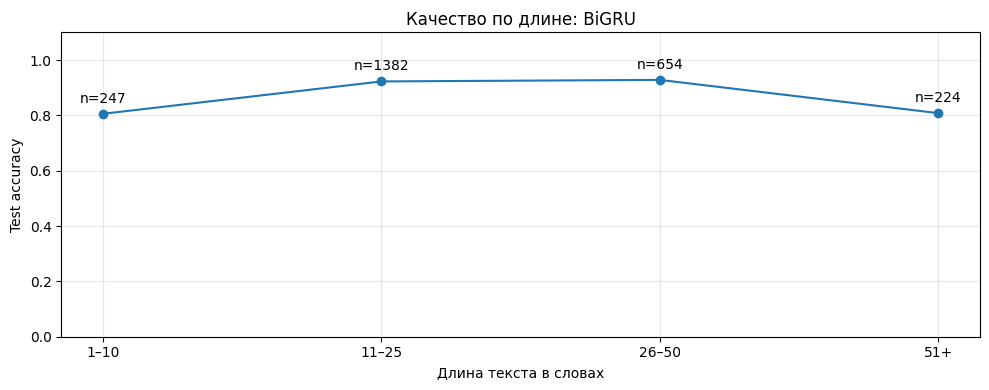

In [43]:
plt.figure(figsize=(10, 4))
plt.plot(group_names, length_results['accuracy'], marker='o')
for i, group in enumerate(group_names):
    count = int(length_results.loc[group, 'count'])
    accuracy = length_results.loc[group, 'accuracy']
    if count > 0:
        plt.annotate(f'n={count}', (i, accuracy), xytext=(0, 8),
                     textcoords='offset points', ha='center')
plt.xlabel('Длина текста в словах')
plt.ylabel('Test accuracy')
plt.title('Качество по длине: ' + best_architecture)
plt.ylim(0, 1.1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Лучшее качество получено на текстах средней длины: accuracy составляет 92,26% для 11–25 слов и 92,81% для 26–50 слов. Короткие сообщения до 10 слов и длинные от 51 слова классифицируются хуже - примерно с одинаковой accuracy около 80%. Таким образом, гипотеза "чем длиннее текст, тем выше качество классификации" не подтверждается как монотонная зависимость. Возможно, на выбранном датасете тестирование гипотезы не совсем релевантно, так как он сильно смещен в сторону коротких текстов.